# 10 · Solvay (1927): Bohr và Einstein / Bohr and Einstein

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/10_solvay.ipynb)

Hai câu hỏi khác nhau: biết đường đi có giữ được vân không, và sóng của **một** electron có nghĩa gì khi phép đo chỉ cho một điểm? Chạy từ trên xuống; không cần dữ liệu ngoài.
*Two different questions: can path knowledge coexist with fringes, and what does the wave of **one** electron mean when detection gives just one point? Run top to bottom; no external data are needed.*

Khe giật lùi theo hồi tưởng của [Bohr (1949)](https://www.marxists.org/reference/subject/philosophy/works/dk/bohr.htm). Màn bán cầu thuộc phản đối được ghi trong thảo luận năm 1927; xem bản dịch biên bản trong [Bacciagaluppi & Valentini](https://arxiv.org/abs/quant-ph/0609184). Đường cong bổ sung dưới đây là cách mô tả hiện đại, không phải công thức được trình bày tại Solvay.
*The recoiling slit follows Bohr's 1949 recollection; the hemispherical screen belongs to the recorded 1927 discussion. The complementarity curve below is a modern formulation, not a formula presented at Solvay.*

## 1. Cú giật và độ nhoè / Recoil and position spread

Gọi $L$ là khoảng cách từ khe đầu đến hai khe, $d$ là khoảng cách giữa hai khe; $\lambda$ là bước sóng electron. Với góc nhỏ, hai đường đi khác nhau về động lượng ngang một lượng
$$\delta p_{\rm recoil}\simeq p\,d/L=hd/(\lambda L).$$
Dịch khe đầu một đoạn $x$ đổi pha tương đối $\phi=2\pi d x/(\lambda L)$. Vì vậy chu kỳ theo **vị trí khe đầu** là $P=\lambda L/d$, và $\delta p_{\rm recoil}=h/P$. Nếu màn cách hai khe một đoạn $L_s$, chu kỳ vân trên màn là $\lambda L_s/d$; chỉ bằng $P$ khi $L_s=L$.
*Small-angle geometry gives the recoil separation above. A first-slit displacement changes the relative phase; $P$ is a period in first-slit coordinates, not generally the screen fringe period.*

Để phân biệt hai cú giật, độ lệch chuẩn động lượng $\sigma_p$ phải **nhỏ hơn nhiều** $\delta p_{\rm recoil}$. Bất định cho $\sigma_x\ge\hbar/(2\sigma_p)$. Với Gaussian đạt dấu bằng,
$$V=\exp[-2\pi^2(\sigma_x/P)^2]=\exp[-\delta p_{\rm recoil}^2/(8\sigma_p^2)],\quad D=\sqrt{1-V^2}.$$
$\sigma_p=\delta p_{\rm recoil}$ chưa đủ để xoá vân; phải tính mức phân biệt thực sự. Gaussian không cho $V=0$ ở độ rộng hữu hạn.
*Resolving recoil requires momentum spread much smaller than the separation. A minimum-uncertainty Gaussian gives the expressions above. Momentum spread equal to the recoil separation does not erase fringes; exact zero visibility requires an infinite Gaussian position spread.*

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import h, hbar
from scipy.integrate import trapezoid

rng = np.random.default_rng(1927)
wavelength = 50e-12  # m
slit_spacing = 1e-6  # m
first_to_double = 0.1  # m
screen_distance = 0.1  # m
period = wavelength * first_to_double / slit_spacing
screen_period = wavelength * screen_distance / slit_spacing
recoil_separation = h * slit_spacing / (wavelength * first_to_double)
print(f"First-slit phase period P = {period * 1e6:.3f} micrometres")
print(f"Screen fringe period = {screen_period * 1e6:.3f} micrometres")
print(f"Recoil separation = {recoil_separation:.6e} kg m/s")
print(f"{'sigma_p / recoil':>18} {'sigma_x (um)':>15} {'sigma_x / P':>14} {'V':>12} {'D':>12}")
for fraction in [1, 0.5, 0.25, 0.1]:
    sigma_p = fraction * recoil_separation
    sigma_x = hbar / (2 * sigma_p)
    V = np.exp(-2 * np.pi**2 * (sigma_x / period)**2)
    D = np.sqrt(1 - V**2)
    assert np.isclose(sigma_x * sigma_p / hbar, 0.5)
    assert np.isclose(V, np.exp(-recoil_separation**2 / (8 * sigma_p**2)))
    print(f"{fraction:18.2f} {sigma_x * 1e6:15.6f} {sigma_x / period:14.6f} {V:12.6g} {D:12.6g}")

# A quantitative threshold for nearly washed-out fringes.
target_V = 0.01
required_sigma_x = period * np.sqrt(-np.log(target_V) / (2 * np.pi**2))
allowed_sigma_p = hbar / (2 * required_sigma_x)
print(f"V <= 1% requires sigma_x >= {required_sigma_x * 1e6:.3f} micrometres")
print(f"Then sigma_p <= {allowed_sigma_p / recoil_separation:.3f} times the recoil separation")

First-slit phase period P = 5.000 micrometres
Screen fringe period = 5.000 micrometres
Recoil separation = 1.325214e-28 kg m/s
  sigma_p / recoil    sigma_x (um)    sigma_x / P            V            D
              1.00        0.397887       0.079577     0.882497     0.470318
              0.50        0.795775       0.159155     0.606531      0.79506
              0.25        1.591549       0.318310     0.135335       0.9908
              0.10        3.978874       0.795775  3.72665e-06            1
V <= 1% requires sigma_x >= 2.415 micrometres
Then sigma_p <= 0.165 times the recoil separation


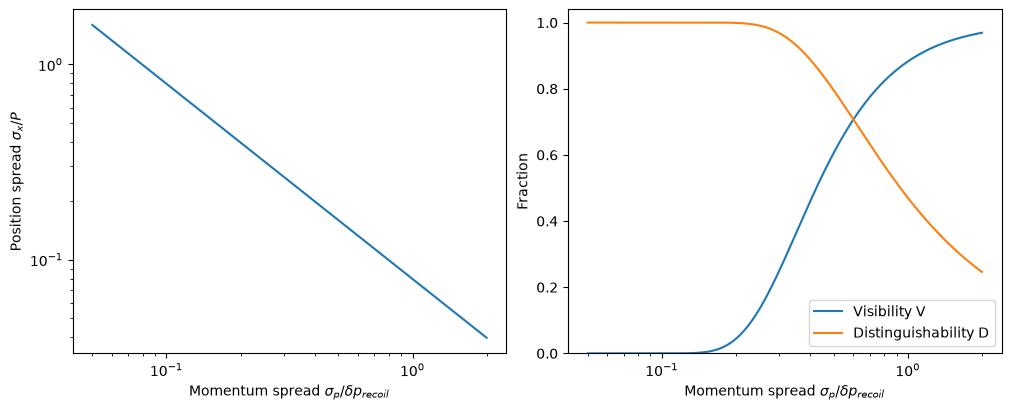

In [2]:
fractions = np.geomspace(0.05, 2, 400)
spread = hbar / (2 * fractions * recoil_separation) / period
contrast = np.exp(-2 * np.pi**2 * spread**2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].loglog(fractions, spread)
axes[0].set(xlabel=r"Momentum spread $\sigma_p/\delta p_{recoil}$", ylabel=r"Position spread $\sigma_x/P$")
axes[1].semilogx(fractions, contrast, label="Visibility V")
axes[1].semilogx(fractions, np.sqrt(1 - contrast**2), label="Distinguishability D")
axes[1].set(xlabel=r"Momentum spread $\sigma_p/\delta p_{recoil}$", ylabel="Fraction", ylim=(0, 1.04))
axes[1].legend()
plt.show()

## 2. Bổ sung và detector / Complementarity and detector states

Hai đường có biên độ bằng nhau, detector ở trạng thái thuần $|m_0\rangle=(1,0)$ và $|m_1\rangle=(V,D)$ với $V^2+D^2=1$. Khi không đọc detector, hệ số giao thoa là độ chồng lấp $\langle m_0|m_1\rangle=V$. $D$ là khả năng phân biệt tối ưu hai trạng thái, không phải tỉ lệ số lần ghi detector ở cơ sở tuỳ chọn này. Với nguồn không hoàn hảo, tổng có thể nhỏ hơn 1.
*Equal path amplitudes and pure detector states give $V=|\langle m_0|m_1\rangle|$ and optimal distinguishability $D=\sqrt{1-V^2}$. In general the duality relation is an inequality.*

Đặt $u$ theo đơn vị chu kỳ vân và $a/d=0{,}25$. Lấy mẫu Monte Carlo đồng thời vị trí và kết quả detector với trọng số
$$I_j(u)=\frac{\operatorname{sinc}^2(\pi u a/d)}4\left|m_{0j}+e^{2\pi i u}m_{1j}\right|^2.$$
Cộng hai kết quả cho $I(u)=\operatorname{sinc}^2(\pi u a/d)[1+V\cos(2\pi u)]/2$. Chuẩn hoá xác suất trên cửa sổ $-4\le u\le4$, cùng cửa sổ mô phỏng web. NumPy dùng `sinc(x) = sin(pi*x)/(pi*x)`.
*Sample the joint position/detector distribution, then discard the detector result. The resulting screen intensity matches the web function. The central peak is unity at $V=1$; probability density still needs integral normalisation.*

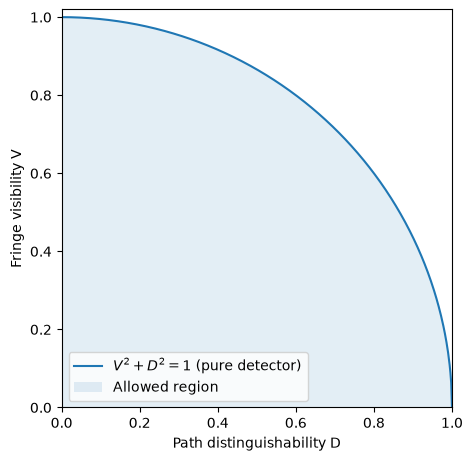

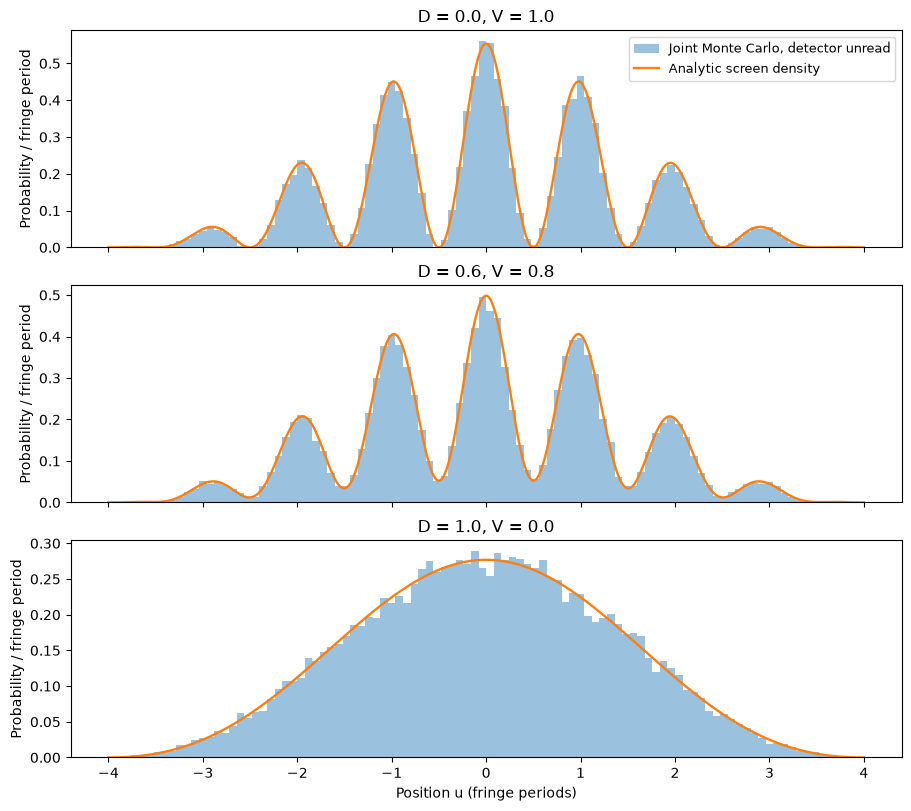

Monte Carlo: 30,000 detections per pattern; all duality checks passed.


In [3]:
def visibility(D):
    return np.sqrt(1 - np.asarray(D)**2)

def screen(u, V, a_over_d=0.25):
    return np.sinc(u * a_over_d)**2 * (1 + V * np.cos(2 * np.pi * u)) / 2

def recoil_argument(D):
    return np.sqrt(-np.log1p(-np.asarray(D)**2)) / (2 * np.pi)

def slit_blur_fringes(sigma_over_period):
    return np.exp(-2 * np.pi**2 * sigma_over_period**2)

assert visibility(0) == 1 and visibility(1) == 0
assert np.isclose(visibility(0.6), 0.8)
assert screen(0, 1) == 1 and screen(0.5, 1) < 1e-12
assert screen(0.5, 0) > 0.4
assert np.allclose(slit_blur_fringes(recoil_argument(np.array([0.2, 0.5, 0.9]))), visibility(np.array([0.2, 0.5, 0.9])), atol=1e-9)

D_grid = np.linspace(0, 1, 501)
fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
ax.plot(D_grid, visibility(D_grid), label=r"$V^2+D^2=1$ (pure detector)")
ax.fill_between(D_grid, 0, visibility(D_grid), alpha=0.12, label="Allowed region")
ax.set(xlabel="Path distinguishability D", ylabel="Fringe visibility V", xlim=(0, 1), ylim=(0, 1.02), aspect="equal")
ax.legend()
plt.show()

u_grid = np.linspace(-4, 4, 4001)
fig, axes = plt.subplots(3, 1, figsize=(9, 8), layout="constrained", sharex=True)
for ax, D in zip(axes, [0, 0.6, 1]):
    V = float(visibility(D))
    marker0, marker1 = np.array([1, 0]), np.array([V, D])
    assert np.isclose(np.vdot(marker0, marker1), V)
    hits, marker_results = [], []
    while len(hits) < 30000:
        candidate_u = rng.uniform(-4, 4, 10000)
        j = rng.integers(0, 2, 10000)
        weight = np.sinc(candidate_u * 0.25)**2 * np.abs(marker0[j] + np.exp(2j * np.pi * candidate_u) * marker1[j])**2 / 4
        accept = rng.random(len(j)) < weight
        hits.extend(candidate_u[accept])
        marker_results.extend(j[accept])
    density = screen(u_grid, V)
    density /= trapezoid(density, u_grid)
    ax.hist(hits[:30000], bins=100, range=(-4, 4), density=True, alpha=0.45, label="Joint Monte Carlo, detector unread")
    ax.plot(u_grid, density, lw=1.7, label="Analytic screen density")
    ax.set(ylabel="Probability / fringe period", title=f"D = {D:.1f}, V = {V:.1f}")
axes[0].legend(fontsize=9)
axes[-1].set_xlabel("Position u (fringe periods)")
plt.show()
print("Monte Carlo: 30,000 detections per pattern; all duality checks passed.")

## 3. Màn bán cầu / The hemispherical screen

Giả sử lỗ điểm phát sóng đẳng hướng vào bán cầu bán kính $R$. Mật độ xác suất theo **diện tích mặt cầu** là $1/(2\pi R^2)$: bằng nhau ở mọi điểm. Đây là lý tưởng hoá bỏ qua hướng tính của một lỗ nhiễu xạ thực. Chọn $\mu=\cos\theta$ đều trong $[0,1]$ và $\varphi$ đều trong $[0,2\pi)$; không chọn $\theta$ đều cho mặt cầu 3D. Canvas web là hình cắt 2D, lấy góc trên cung đều.
*Assume isotropic emission into a hemisphere. Probability per surface area is uniform, an idealisation of a point hole. In 3D sample cos(theta) uniformly, not theta. The web canvas shows a 2D section with uniform arc angles.*

Mỗi lần chỉ có một chấm; phân bố nhiều lần phát hiện chưa giải thích sự thay đổi của $\psi$ cho một lần đo. Minh hoạ sự sụp đổ tức thời là điều Einstein chất vấn, không phải bằng chứng truyền tín hiệu nhanh hơn ánh sáng.
*Each event gives one dot. The distribution of many events does not settle how to interpret the change of one electron's wave. Instantaneous collapse is the issue Einstein questioned, not evidence for faster-than-light signalling.*

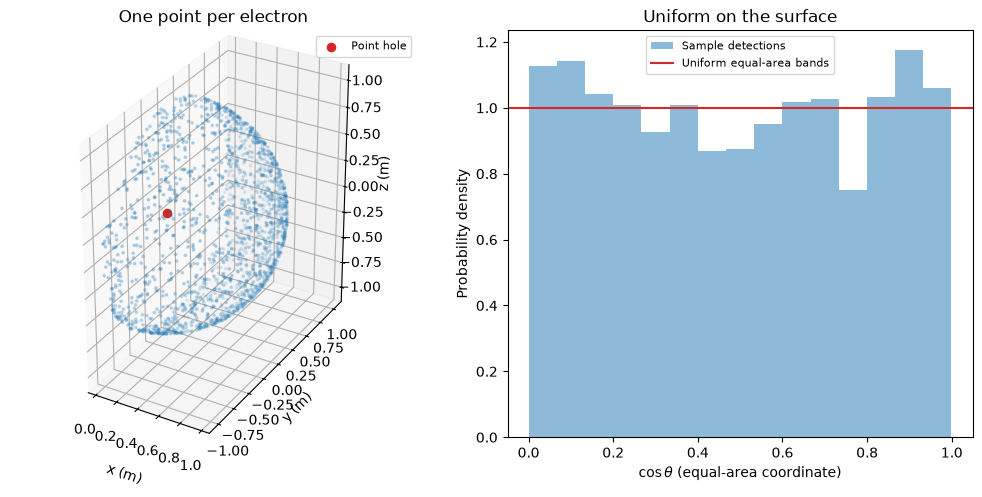

Uniform surface density: 0.159155 per square metre
1800 independent detections, one per electron; all notebook checks passed.


In [4]:
R = 1.0  # m
N = 1800
mu = rng.uniform(0, 1, N)
phi = rng.uniform(0, 2 * np.pi, N)
x = R * mu
y = R * np.sqrt(1 - mu**2) * np.cos(phi)
z = R * np.sqrt(1 - mu**2) * np.sin(phi)
assert np.allclose(x*x + y*y + z*z, R*R)
assert np.all(x >= 0)
area_density = 1 / (2 * np.pi * R**2)
assert np.isclose(area_density * 2 * np.pi * R**2, 1)
counts, _ = np.histogram(mu, bins=10, range=(0, 1))
assert np.max(np.abs(counts - N/10)) < 5 * np.sqrt(N/10 * 0.9)
fig = plt.figure(figsize=(10, 4.8), layout="constrained")
ax = fig.add_subplot(121, projection="3d")
ax.scatter(x, y, z, s=3, alpha=0.5)
ax.scatter([0], [0], [0], s=35, color="tab:red", label="Point hole")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="One point per electron", box_aspect=(0.5, 1, 1))
ax.legend(fontsize=8)
ax2 = fig.add_subplot(122)
ax2.hist(mu, bins=15, density=True, alpha=0.5, label="Sample detections")
ax2.axhline(1, color="tab:red", label="Uniform equal-area bands")
ax2.set(xlabel=r"$\cos\theta$ (equal-area coordinate)", ylabel="Probability density", title="Uniform on the surface")
ax2.legend(fontsize=8)
plt.show()
print(f"Uniform surface density: {area_density:.6f} per square metre")
print(f"{N} independent detections, one per electron; all notebook checks passed.")

### Giới hạn mô hình / Model limits

Lò xo và độ rung trên web là sơ đồ được phóng đại; Gaussian mô tả bất định lượng tử hoặc phép trung bình trên vị trí, không khẳng định khe đang chạy theo quỹ đạo cổ điển. $D$ là độ phân biệt chuẩn hoá, không phải một đơn vị độ chính xác thiết bị. Mô hình bỏ qua mất kết hợp ngoài ý muốn, độ rộng năng lượng chùm và hiệu suất detector.
*The exaggerated spring motion illustrates quantum position uncertainty or averaging over positions, not a measured classical trajectory. D is normalised distinguishability rather than an instrumental precision unit. Uncontrolled decoherence, beam energy spread and detector efficiency are omitted.*